In [3]:
import pandas as pd 
import numpy as np
df= pd.read_csv("Covid Data.csv")

In [4]:
df.head()


,USMER,MEDICAL_UNIT,SEX,PATIENT_TYPE,DATE_DIED,INTUBED,PNEUMONIA,AGE,PREGNANT,DIABETES,...,ASTHMA,INMSUPR,HIPERTENSION,OTHER_DISEASE,CARDIOVASCULAR,OBESITY,RENAL_CHRONIC,TOBACCO,CLASIFFICATION_FINAL,ICU
0,2,1,1,1,03/05/2020,97,1,65,2,2,...,2,2,1,2,2,2,2,2,3,97
1,2,1,2,1,03/06/2020,97,1,72,97,2,...,2,2,1,2,2,1,1,2,5,97
2,2,1,2,2,09/06/2020,1,2,55,97,1,...,2,2,2,2,2,2,2,2,3,2
3,2,1,1,1,12/06/2020,97,2,53,2,2,...,2,2,2,2,2,2,2,2,7,97
4,2,1,2,1,21/06/2020,97,2,68,97,1,...,2,2,1,2,2,2,2,2,3,97


In [5]:
df.columns

Index(['USMER', 'MEDICAL_UNIT', 'SEX', 'PATIENT_TYPE', 'DATE_DIED', 'INTUBED',
       'PNEUMONIA', 'AGE', 'PREGNANT', 'DIABETES', 'COPD', 'ASTHMA', 'INMSUPR',
       'HIPERTENSION', 'OTHER_DISEASE', 'CARDIOVASCULAR', 'OBESITY',
       'RENAL_CHRONIC', 'TOBACCO', 'CLASIFFICATION_FINAL', 'ICU'],
      dtype='str')

In [6]:
df.shape

(1048575, 21)

In [7]:
pd.set_option('display.float_format', '{:,.2f}'.format)

In [8]:
df["AGE"].describe()

count   1,048,575.00
mean           41.79
std            16.91
min             0.00
25%            30.00
50%            40.00
75%            53.00
max           121.00
Name: AGE, dtype: float64

In [9]:
df["PATIENT_TYPE"].value_counts(dropna=False)

PATIENT_TYPE
1    848544
2    200031
Name: count, dtype: int64

In [10]:
print(df['AGE'].describe())
print(df['PATIENT_TYPE'].value_counts())

count   1,048,575.00
mean           41.79
std            16.91
min             0.00
25%            30.00
50%            40.00
75%            53.00
max           121.00
Name: AGE, dtype: float64
PATIENT_TYPE
1    848544
2    200031
Name: count, dtype: int64


In [11]:
df["AGE"].mean()


np.float64(41.794102472403026)

In [12]:
df["AGE"].median()

np.float64(40.0)

In [13]:
df["PATIENT_TYPE"].value_counts(normalize=True) * 100

PATIENT_TYPE
1   80.92
2   19.08
Name: proportion, dtype: float64

In [14]:
print("Diabetes:", (df["DIABETES"] == 1).sum())

print("Hypertension:", (df["HIPERTENSION"] == 1).sum())

print("Obesity:", (df["OBESITY"] == 1).sum())

Diabetes: 124989
Hypertension: 162729
Obesity: 159816


In [15]:
df["DIABETES"].value_counts(dropna=False)

DIABETES
2     920248
1     124989
98      3338
Name: count, dtype: int64

In [16]:
########### phase 3 ############

In [17]:
hospitalized = (df["PATIENT_TYPE"] == 2).sum()
total = len(df)
percentage = (hospitalized / total) * 100
print(percentage)

19.07646091123668


In [18]:
hospitalized_age = df.loc[df["PATIENT_TYPE"] == 2, "AGE"].mean()

non_hospitalized_age = df.loc[df["PATIENT_TYPE"] == 1, "AGE"].mean()

difference = hospitalized_age - non_hospitalized_age

print("Average age of hospitalized patients:", hospitalized_age)
print("Average age of non-hospitalized patients:", non_hospitalized_age)
print("Difference:", difference)

Average age of hospitalized patients: 52.77003064524999
Average age of non-hospitalized patients: 39.20669876871441
Difference: 13.563331876535578


In [19]:
older_hospitalized = ((df["AGE"] > 60) &(df["PATIENT_TYPE"] == 2)).sum()

print(older_hospitalized)

74919


In [20]:
diabetes_patients = df["DIABETES"] == 1

hospitalized_diabetes = (
    diabetes_patients & (df["PATIENT_TYPE"] == 2)
).sum()

total_diabetes = diabetes_patients.sum()

percentage_diabetes = (
    hospitalized_diabetes / total_diabetes
) * 100

print("Hospitalized patients with diabetes:", hospitalized_diabetes)
print("Total patients with diabetes:", total_diabetes)
print("Percentage:", percentage_diabetes)

Hospitalized patients with diabetes: 57896
Total patients with diabetes: 124989
Percentage: 46.32087623710886


In [21]:

hypertension_patients = df["HIPERTENSION"] == 1

hospitalized_hypertension = (
    hypertension_patients & (df["PATIENT_TYPE"] == 2)
).sum()

total_hypertension = hypertension_patients.sum()

percentage_hypertension = (
    hospitalized_hypertension / total_hypertension
) * 100

print("Hospitalized patients with hypertension:", hospitalized_hypertension)
print("Total patients with hypertension:", total_hypertension)
print("Percentage:", percentage_hypertension)

Hospitalized patients with hypertension: 65591
Total patients with hypertension: 162729
Percentage: 40.30689059725064


In [22]:
pneumonia_patients = df["PNEUMONIA"] == 1

hospitalized_pneumonia = (
    pneumonia_patients & (df["PATIENT_TYPE"] == 2)
).sum()

total_pneumonia = pneumonia_patients.sum()

percentage_pneumonia = (
    hospitalized_pneumonia / total_pneumonia
) * 100

print("Hospitalized patients with pneumonia:", hospitalized_pneumonia)
print("Total patients with pneumonia:", total_pneumonia)
print("Percentage:", percentage_pneumonia)

Hospitalized patients with pneumonia: 116843
Total patients with pneumonia: 140038
Percentage: 83.43663862665848


In [23]:
########### phase 4 ################

In [24]:
bins = [0, 18, 30, 45, 60, 75, float('inf')]
labels = ['0-18', '19-30', '31-45', '46-60', '61-75', '75+']

df['AGE_GROUP'] = pd.cut(
    df['AGE'],
    bins=bins,
    labels=labels,
    right=True,
    include_lowest=True
)

In [25]:
df['AGE_GROUP'].value_counts().idxmax()

'31-45'

In [26]:
df['AGE_GROUP'].value_counts().sort_index()

AGE_GROUP
0-18      59714
19-30    221473
31-45    357948
46-60    265068
61-75    107830
75+       36542
Name: count, dtype: int64

In [30]:

hospitalized_by_age = df.groupby(
    'AGE_GROUP',
    observed=False
)['PATIENT_TYPE'].apply(lambda x: (x == 2).sum())

print(hospitalized_by_age)


AGE_GROUP
0-18     12285
19-30    13217
31-45    37344
46-60    62266
61-75    52254
75+      22665
Name: PATIENT_TYPE, dtype: int64


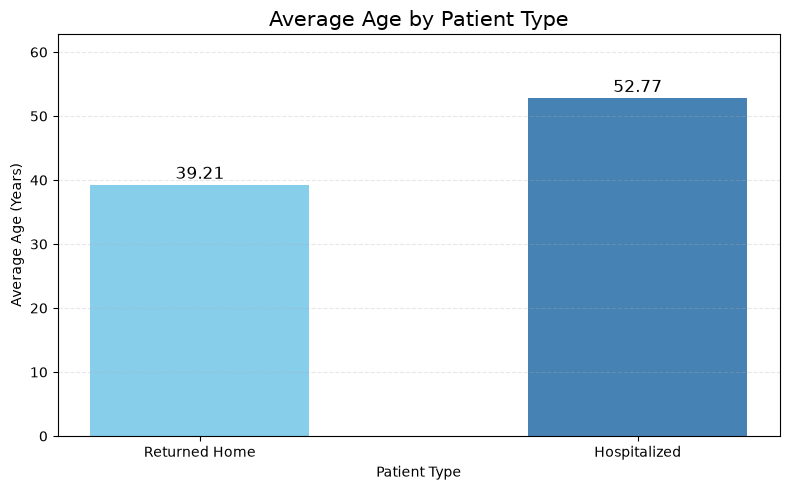

In [31]:
import matplotlib.pyplot as plt
avg_age = df.groupby('PATIENT_TYPE')['AGE'].mean()

labels = ['Returned Home', 'Hospitalized']

values = [
    avg_age.loc[1],
    avg_age.loc[2]
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    labels,
    values,
    color=['skyblue', 'steelblue'],
    width=0.5
)
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f'{height:.2f}',
        ha='center',
        fontsize=12
    )

plt.title('Average Age by Patient Type', fontsize=15)
plt.xlabel('Patient Type')
plt.ylabel('Average Age (Years)')
plt.ylim(0, max(values) + 10)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()



In [32]:

age_analysis = df.groupby(
    'AGE_GROUP',
    observed=False
).agg(
    Total_Patients=('PATIENT_TYPE', 'count'),
    Hospitalized_Patients=(
        'PATIENT_TYPE',
        lambda x: (x == 2).sum()
    )
)

age_analysis['Hospitalization_Rate'] = (
    age_analysis['Hospitalized_Patients']
    / age_analysis['Total_Patients']
) * 100

print(age_analysis)

print(
    'Highest hospitalization rate:',
    age_analysis['Hospitalization_Rate'].idxmax()
)


           Total_Patients  Hospitalized_Patients  Hospitalization_Rate
AGE_GROUP                                                             
0-18                59714                  12285                 20.57
19-30              221473                  13217                  5.97
31-45              357948                  37344                 10.43
46-60              265068                  62266                 23.49
61-75              107830                  52254                 48.46
75+                 36542                  22665                 62.02
Highest hospitalization rate: 75+


In [34]:
age_by_gender = df.groupby(
    ['SEX', 'PATIENT_TYPE']
)['AGE'].mean().unstack()

print(age_by_gender)


PATIENT_TYPE     1     2
SEX                     
1            39.27 52.41
2            39.14 53.02


In [36]:
both_conditions = df[
    (df['DIABETES'] == 1) &
    (df['HIPERTENSION'] == 1)
]

neither_condition = df[
    (df['DIABETES'] == 2) &
    (df['HIPERTENSION'] == 2)
]

rate_both = (both_conditions['PATIENT_TYPE'] == 2).mean() * 100

rate_neither = (neither_condition['PATIENT_TYPE'] == 2).mean() * 100

print("Diabetes and hypertension:", rate_both, "%")
print("Neither condition:", rate_neither, "%")


Diabetes and hypertension: 52.281610762657934 %
Neither condition: 13.33972149555865 %


In [39]:
condition_cols = [
    'DIABETES',
    'HIPERTENSION',
    'OBESITY',
    'ASTHMA',
    'COPD',
    'CARDIOVASCULAR'
]

df['CONDITION_COUNT'] = (
    df[condition_cols] == 1
).sum(axis=1)

print(df[['CONDITION_COUNT']].head())


   CONDITION_COUNT
0                1
1                2
2                1
3                0
4                2


In [40]:
condition_distribution = df['CONDITION_COUNT'].value_counts().sort_index()

print(condition_distribution)


CONDITION_COUNT
0    698449
1    224963
2     91861
3     27900
4      4615
5       630
6       157
Name: count, dtype: int64


In [41]:
zero_conditions = df[df['CONDITION_COUNT'] == 0]

multiple_conditions = df[df['CONDITION_COUNT'] >= 2]

rate_zero = (
    (zero_conditions['PATIENT_TYPE'] == 2).mean() * 100
)

rate_multiple = (
    (multiple_conditions['PATIENT_TYPE'] == 2).mean() * 100
)

print("Zero conditions:", rate_zero, "%")
print("Multiple conditions:", rate_multiple, "%")


Zero conditions: 12.621107625610458 %
Multiple conditions: 43.89556018951288 %


In [42]:
print(df.groupby('PATIENT_TYPE')['AGE'].mean())
diabetes = df[df['DIABETES'] == 1]
print("Diabetes hospitalization rate:",
      (diabetes['PATIENT_TYPE'] == 2).mean() * 100)
hypertension = df[df['HIPERTENSION'] == 1]
print("Hypertension hospitalization rate:",
      (hypertension['PATIENT_TYPE'] == 2).mean() * 100)
print(df.groupby('SEX').apply(
    lambda x: (x['PATIENT_TYPE'] == 2).mean() * 100,
    include_groups=False
))


PATIENT_TYPE
1   39.21
2   52.77
Name: AGE, dtype: float64
Diabetes hospitalization rate: 46.32087623710886
Hypertension hospitalization rate: 40.30689059725064
SEX
1   15.56
2   22.60
dtype: float64


In [43]:
print(df.groupby('AGE_GROUP', observed=False).apply(
    lambda x: (x['PATIENT_TYPE'] == 2).mean() * 100,
    include_groups=False
))
print(df.groupby('CONDITION_COUNT').apply(
    lambda x: (x['PATIENT_TYPE'] == 2).mean() * 100,
    include_groups=False
))


AGE_GROUP
0-18    20.57
19-30    5.97
31-45   10.43
46-60   23.49
61-75   48.46
75+     62.02
dtype: float64
CONDITION_COUNT
0   12.62
1   25.31
2   41.44
3   49.47
4   57.51
5   58.25
6   33.12
dtype: float64


In [44]:
print(df.isnull().sum())
condition_cols = [
    'DIABETES', 'HIPERTENSION', 'OBESITY',
    'ASTHMA', 'COPD', 'CARDIOVASCULAR'
]
for col in condition_cols:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


USMER                   0
MEDICAL_UNIT            0
SEX                     0
PATIENT_TYPE            0
DATE_DIED               0
INTUBED                 0
PNEUMONIA               0
AGE                     0
PREGNANT                0
DIABETES                0
COPD                    0
ASTHMA                  0
INMSUPR                 0
HIPERTENSION            0
OTHER_DISEASE           0
CARDIOVASCULAR          0
OBESITY                 0
RENAL_CHRONIC           0
TOBACCO                 0
CLASIFFICATION_FINAL    0
ICU                     0
AGE_GROUP               0
CONDITION_COUNT         0
dtype: int64

DIABETES:
DIABETES
2     920248
1     124989
98      3338
Name: count, dtype: int64

HIPERTENSION:
HIPERTENSION
2     882742
1     162729
98      3104
Name: count, dtype: int64

OBESITY:
OBESITY
2     885727
1     159816
98      3032
Name: count, dtype: int64

ASTHMA:
ASTHMA
2     1014024
1       31572
98       2979
Name: count, dtype: int64

COPD:
COPD
2     1030510
1       15062
98  

In [45]:
print("Total records:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Average age:", df['AGE'].mean())
print("Median age:", df['AGE'].median())

print("\nHospitalization rate:")
print((df['PATIENT_TYPE'] == 2).mean() * 100)

print("\nHospitalization rate by age group:")
print(df.groupby('AGE_GROUP', observed=False).apply(
    lambda x: (x['PATIENT_TYPE'] == 2).mean() * 100,
    include_groups=False
))

print("\nHospitalization rate by condition count:")
print(df.groupby('CONDITION_COUNT').apply(
    lambda x: (x['PATIENT_TYPE'] == 2).mean() * 100,
    include_groups=False
))


Total records: 1048575
Number of columns: 23
Average age: 41.794102472403026
Median age: 40.0

Hospitalization rate:
19.07646091123668

Hospitalization rate by age group:
AGE_GROUP
0-18    20.57
19-30    5.97
31-45   10.43
46-60   23.49
61-75   48.46
75+     62.02
dtype: float64

Hospitalization rate by condition count:
CONDITION_COUNT
0   12.62
1   25.31
2   41.44
3   49.47
4   57.51
5   58.25
6   33.12
dtype: float64


In [ ]:
age_rates = df.groupby(
    'AGE_GROUP', observed=False
    
).apply(
    lambda x: (x['PATIENT_TYPE'] == 2).mean() * 100,
    include_groups=False
)

print("Highest age-group rate:")
print(age_rates.idxmax(), age_rates.max())

# Finding 2: Condition counts with highest hospitalization rates
condition_rates = df.groupby('CONDITION_COUNT').apply(
    lambda x: (x['PATIENT_TYPE'] == 2).mean() * 100,
    include_groups=False
)

print("Highest condition-count rate:")
print(condition_rates.idxmax(), condition_rates.max())


Highest age-group rate:
75+ 62.02451973072082
Highest condition-count rate:
5 58.25396825396826
